In [1]:
import os
import sys
sys.path.insert(0, "./../../Python/test_treatments") # add path to the model

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import random
from pathlib import Path
import datetime

## Importing the model, models differ on their initial conditions, one being a concentration and the other a protein count

# to match Austin's ouput and use his functions, simulation with ODE should use omega=1 and stochastic with omega=200 (the default)
from cell_cycle_death_model import model


sys.path.insert(0, "./../../Python/cellular_cycle")
from model_fxns import * # functions to evaluate simulation output; includes plotObs()

##Import the simulator: for ODE and stochastic simulation :
from pysb.simulator import BngSimulator
from pysb.simulator import ScipyOdeSimulator


# Directory containing cell fate data
DATADIR = Path('../data/Exp_Intermitotic_Times/')

# Where to save large simulation output files
SAVE_DIR = Path(Path.home(),'ECM_mod_output')
if not SAVE_DIR.exists():
    SAVE_DIR.mkdir()

OVERWRITE = True # Overwrite existing simulation files

CURDATE = datetime.datetime.now().strftime('%Y%m%d')

In [31]:
# t = np.linspace(0, 10000, 100001)
t = np.linspace(0, 20000, 200001)
# t = np.linspace(0, 50000, 500001)

model.parameters['AKT'].value = 0.3
model.parameters['ERK'].value = 0.2
model.parameters['FAK'].value = 0.4

In [32]:
# Importing the parameters:
new_param = pd.read_csv(os.getcwd()+ './../../Python/test_treatments/parameters.csv')
del new_param['Stress']
for key in new_param.keys():
    try:
        if model.parameters[key].value != new_param[key][0]:
            model.parameters[key].value = new_param[key]
    except:
        print(key)
model.parameters['omega'].value = 200

b
Hippo_tot
Yap_tot
AKT_tot
ERK_tot
FAK_tot
skp2_tot
p21_tot
cdh1_tot
CycD_tot
K_1E2F
V_1E2F
k_cd4
k_myc1
k_CE
d_CE
K_i13
K_i14
V_sac
V_da
V_sec
V_de
V_sf
V_fs
V_dfa
v_scdh1a
v_2fak
v_s2p21
K_AFAK
K_dfa
K_fs
K_cf
K_cac
K_cec
K_da
K_de
K_sp21
k_dcdh1a
K_p21fak.1
k_CDF
K_DF
K_dcescp2


In [33]:
# Setting initial concentrations '/../model_data/initial_concentrations.csv'
initial_concentrations = pd.read_csv(os.getcwd() + './../../Python/model_data/initial_concentrations.csv')
for key in initial_concentrations.keys():
    try:
        model.parameters[key].value = initial_concentrations[key][0] / model.parameters['omega'].value
    except:
        print(key)

In [34]:
thr = [0.26, 0.18]
return_plot = False
from Check_Model_Consistency import Check_Model_Consistency

In [35]:
variable_range, check, tmp_score = Check_Model_Consistency(model, thr = thr, return_plot = return_plot)

2024-02-26 11:03:42.123 - pysb.simulator.scipyode - WARNING - [cell_cycle_death_model] This system of ODEs will be evaluated in pure Python. This may be slow for large models. We recommend installing the 'cython' package for compiling the ODEs to C code. This warning can be suppressed by specifying compiler='python'.


In [36]:
death_mod={'obsBAX': 186 ,'obsBAXmBCL2': 13, 'obsBH3': 0, 'obsBH3BCL2': 7, 'obsBAXm': 0, 'obsBCL2': 149}
for prot in death_mod:
    variable_range[prot] = len(variable_range['obsCdc20'])*[death_mod[prot]]

In [38]:
Initial=[]
for var in list(variable_range.keys()):
    # print(variable_range[var][a])
    Initial = Initial + [int(variable_range[var][0])]

In [39]:
Initial

[10,
 110,
 454,
 8,
 191,
 91,
 22,
 21,
 165,
 3,
 1,
 106,
 1,
 2,
 7,
 31,
 87,
 9,
 148,
 186,
 13,
 0,
 7,
 0,
 149,
 0,
 0,
 0,
 0,
 0,
 0]

In [51]:
observables=['obsBAXm']

In [50]:
sim_stoch = BngSimulator(model, tspan=t, verbose=False);
sim_stoch_res = sim_stoch.run(method='ssa', initials=Initial, verbose=False, seed=33); 

<Axes: xlabel='Time (h)', ylabel='Concentration'>

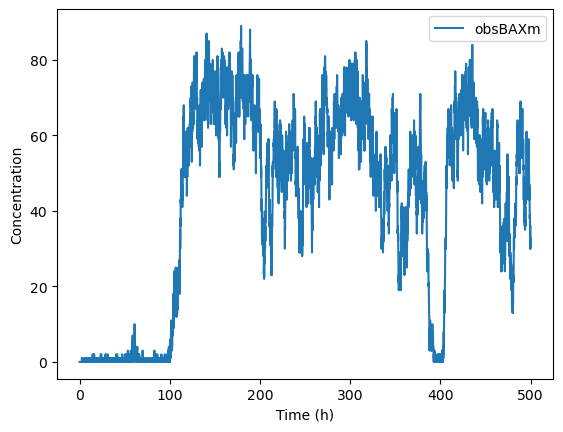

In [52]:
plotObs(model=sim_stoch_res.all, obs=observables, times=t, tpos=range(0,5000), legend=True)

In [61]:
death = np.array([i for i,x in enumerate(sim_stoch_res.observables['obsBAXm']) if x > 20]) if len([i for i,x in enumerate(sim_stoch_res.observables['obsBAXm']) if x > 25])>20 else np.array([])


In [62]:
t[death[0]]

104.9

In [82]:
from peakfinder import peakfinder

In [113]:
num_runs=10
len_runs=500
t = np.linspace(0, len_runs, len_runs*10+1)

thr = [0.26, 0.18]
return_plot = False
from Check_Model_Consistency import Check_Model_Consistency
variable_range, check, tmp_score = Check_Model_Consistency(model, thr = thr, return_plot = return_plot)
death_mod={'obsBAX': 186 ,'obsBAXmBCL2': 13, 'obsBH3': 0, 'obsBH3BCL2': 7, 'obsBAXm': 0, 'obsBCL2': 149}
for prot in death_mod:
    variable_range[prot] = len(variable_range['obsCdc20'])*[death_mod[prot]]
Initial=[]
for var in list(variable_range.keys()):
    # print(variable_range[var][a])
    Initial = Initial + [int(variable_range[var][0])]    

tot_time_death = 0
tot_time_div = len_runs*num_runs
num_dead = 0
num_divs = 0

2024-02-26 16:46:09.423 - pysb.simulator.scipyode - WARNING - [cell_cycle_death_model] This system of ODEs will be evaluated in pure Python. This may be slow for large models. We recommend installing the 'cython' package for compiling the ODEs to C code. This warning can be suppressed by specifying compiler='python'.


In [114]:
for ii in range(num_runs):
    sim_stoch = BngSimulator(model, tspan=t, verbose=False)
    sim_stoch_res = sim_stoch.run(method='ssa', initials=Initial, verbose=False)
    death = np.array([i for i,x in enumerate(sim_stoch_res.observables['obsBAXm']) if x > 20]) if len([i for i,x in enumerate(sim_stoch_res.observables['obsBAXm']) if x > 25])>20 else np.array([])
    a, max_tmp_cdc = peakfinder(sim_stoch_res.observables['obsCdc20'], thr[0]*model.parameters['omega'].value, thr[0]*model.parameters['omega'].value, 1, includeEndpoints=1)
    if len(death) == 0:
        tot_time_death = tot_time_death+len_runs
    else:
        tot_time_death = tot_time_death+t[death[0]]
        num_dead+=1
    num_divs+=len(max_tmp_cdc)  

death_rate = num_dead/tot_time_death
div_rate = num_divs/tot_time_div


In [130]:
[x for x in max_tmp_cdc if x < death[0]]

[5, 225]

In [94]:
def runDeathDiv(AKT=0.3, ERK=0.2, FAK=0.4, num_runs=10, len_runs=500):
    model.parameters['AKT'].value = AKT
    model.parameters['ERK'].value = ERK
    model.parameters['FAK'].value = FAK
    t = np.linspace(0, len_runs, len_runs*10+1)
    
    thr = [0.26, 0.18]
    return_plot = False
    from Check_Model_Consistency import Check_Model_Consistency
    variable_range, check, tmp_score = Check_Model_Consistency(model, thr = thr, return_plot = return_plot)
    death_mod={'obsBAX': 186 ,'obsBAXmBCL2': 13, 'obsBH3': 0, 'obsBH3BCL2': 7, 'obsBAXm': 0, 'obsBCL2': 149}
    for prot in death_mod:
        variable_range[prot] = len(variable_range['obsCdc20'])*[death_mod[prot]]
    Initial=[]
    for var in list(variable_range.keys()):
        # print(variable_range[var][a])
        Initial = Initial + [int(variable_range[var][0])]    

    tot_time_death = 0
    tot_time_div = len_runs*num_runs
    num_dead = 0
    num_divs = 0
    for ii in range(num_runs):
        sim_stoch = BngSimulator(model, tspan=t, verbose=False)
        sim_stoch_res = sim_stoch.run(method='ssa', initials=Initial, verbose=False)
        death = np.array([i for i,x in enumerate(sim_stoch_res.observables['obsBAXm']) if x > 20]) if len([i for i,x in enumerate(sim_stoch_res.observables['obsBAXm']) if x > 25])>20 else np.array([])
        a, max_tmp_cdc = peakfinder(sim_stoch_res.observables['obsCdc20'], thr[0]*model.parameters['omega'].value, thr[0]*model.parameters['omega'].value, 1, includeEndpoints=1)
        if len(death) == 0:
            tot_time_death = tot_time_death+len_runs
        else:
            tot_time_death = tot_time_death+t[death[0]]
            num_dead+=1
        num_divs+=len(max_tmp_cdc)  
        
    death_rate = num_dead/tot_time_death
    div_rate = num_divs/tot_time_div
    return death_rate, div_rate
            

In [131]:
def runDiv_w_Death(AKT=0.3, ERK=0.2, FAK=0.4, num_runs=10, len_runs=500):
    model.parameters['AKT'].value = AKT
    model.parameters['ERK'].value = ERK
    model.parameters['FAK'].value = FAK
    t = np.linspace(0, len_runs, len_runs*10+1)
    
    thr = [0.26, 0.18]
    return_plot = False
    from Check_Model_Consistency import Check_Model_Consistency
    variable_range, check, tmp_score = Check_Model_Consistency(model, thr = thr, return_plot = return_plot)
    death_mod={'obsBAX': 186 ,'obsBAXmBCL2': 13, 'obsBH3': 0, 'obsBH3BCL2': 7, 'obsBAXm': 0, 'obsBCL2': 149}
    for prot in death_mod:
        variable_range[prot] = len(variable_range['obsCdc20'])*[death_mod[prot]]
    Initial=[]
    for var in list(variable_range.keys()):
        # print(variable_range[var][a])
        Initial = Initial + [int(variable_range[var][0])]    

    tot_time_death = 0
    tot_time_div = 0
    num_dead = 0
    num_divs = 0
    for ii in range(num_runs):
        sim_stoch = BngSimulator(model, tspan=t, verbose=False)
        sim_stoch_res = sim_stoch.run(method='ssa', initials=Initial, verbose=False)
        death = np.array([i for i,x in enumerate(sim_stoch_res.observables['obsBAXm']) if x > 20]) if len([i for i,x in enumerate(sim_stoch_res.observables['obsBAXm']) if x > 25])>20 else np.array([])
        a, max_tmp_cdc = peakfinder(sim_stoch_res.observables['obsCdc20'], thr[0]*model.parameters['omega'].value, thr[0]*model.parameters['omega'].value, 1, includeEndpoints=1)
        
        if len(death) == 0:
            tot_time_death = tot_time_death+len_runs
            tot_time_div = tot_time_div+len_runs
            num_divs+=len(max_tmp_cdc) 
        else:
            tot_time_death = tot_time_death+t[death[0]]
            tot_time_div = tot_time_div+t[death[0]]
            num_dead+=1
            num_divs+=len([x for x in max_tmp_cdc if x < death[0]])  
        
    death_rate = num_dead/tot_time_death
    div_rate = num_divs/tot_time_div
    return death_rate, div_rate
            

In [132]:
test, test1 = runDiv_w_Death(AKT=0.6, ERK=0.2, FAK=1, num_runs=10, len_runs=500)

2024-02-26 16:53:28.576 - pysb.simulator.scipyode - WARNING - [cell_cycle_death_model] This system of ODEs will be evaluated in pure Python. This may be slow for large models. We recommend installing the 'cython' package for compiling the ODEs to C code. This warning can be suppressed by specifying compiler='python'.


In [135]:
test

0.007628928898382666

In [136]:
test1

0.03356728715288373

In [107]:
model.parameters['CycDi_0'].value = 0

In [101]:
concs = [0, 0.001, 0.01, 0.025, 0.05, 0.075, 0.1, 0.25, 0.5, 1, 2, 5, 10]
death_rate_di = dict([(conc, []) for conc in concs])
div_rate_di = dict([(conc, []) for conc in concs])

In [102]:
for conc in concs:
    for i in range(3):
        model.parameters['CycDi_0'].value = conc
        tmp_death, tmp_div = runDeathDiv(AKT=0.6, ERK=0.2, FAK=1, num_runs=25, len_runs=500)
        death_rate_di[conc].append(tmp_death)
        div_rate_di[conc].append(tmp_div)
    

2024-02-26 12:46:48.030 - pysb.simulator.scipyode - WARNING - [cell_cycle_death_model] This system of ODEs will be evaluated in pure Python. This may be slow for large models. We recommend installing the 'cython' package for compiling the ODEs to C code. This warning can be suppressed by specifying compiler='python'.
2024-02-26 12:47:33.163 - pysb.simulator.scipyode - WARNING - [cell_cycle_death_model] This system of ODEs will be evaluated in pure Python. This may be slow for large models. We recommend installing the 'cython' package for compiling the ODEs to C code. This warning can be suppressed by specifying compiler='python'.
2024-02-26 12:48:09.868 - pysb.simulator.scipyode - WARNING - [cell_cycle_death_model] This system of ODEs will be evaluated in pure Python. This may be slow for large models. We recommend installing the 'cython' package for compiling the ODEs to C code. This warning can be suppressed by specifying compiler='python'.
2024-02-26 12:48:36.516 - pysb.simulator.sc

2024-02-26 12:58:41.010 - pysb.simulator.scipyode - WARNING - [cell_cycle_death_model] This system of ODEs will be evaluated in pure Python. This may be slow for large models. We recommend installing the 'cython' package for compiling the ODEs to C code. This warning can be suppressed by specifying compiler='python'.
2024-02-26 12:59:06.320 - pysb.simulator.scipyode - WARNING - [cell_cycle_death_model] This system of ODEs will be evaluated in pure Python. This may be slow for large models. We recommend installing the 'cython' package for compiling the ODEs to C code. This warning can be suppressed by specifying compiler='python'.
2024-02-26 12:59:32.361 - pysb.simulator.scipyode - WARNING - [cell_cycle_death_model] This system of ODEs will be evaluated in pure Python. This may be slow for large models. We recommend installing the 'cython' package for compiling the ODEs to C code. This warning can be suppressed by specifying compiler='python'.
2024-02-26 12:59:58.988 - pysb.simulator.sc

In [137]:
death_rate_di

{0: [0.0061512720830667784, 0.005354565348977975, 0.004729343606518611],
 0.001: [0.005728232715680414, 0.004926530437390224, 0.004906570715950444],
 0.01: [0.006281249214843848, 0.0052431511338314335, 0.004284091120755491],
 0.025: [0.005657708628005658, 0.005955642375586631, 0.005131055714713302],
 0.05: [0.006316454363617221, 0.006013807702484905, 0.005451373746184037],
 0.075: [0.0052501476604029495, 0.005067088248408934, 0.0055289347585698485],
 0.1: [0.007584951456310679, 0.006427595811350063, 0.004793264421473824],
 0.25: [0.005138416083242341, 0.004911276718413016, 0.006476851731910153],
 0.5: [0.004729493532931669, 0.004649000464900046, 0.007585641897017326],
 1: [0.005850661856122473, 0.004396570674873598, 0.0050784856879039705],
 2: [0.005396290050590219, 0.004602903665062042, 0.007363553356307619],
 5: [0.005354440693749273, 0.006975446428571428, 0.007466252538525863],
 10: [0.005457770500750442, 0.0032538313864575535, 0.004225999081304547]}

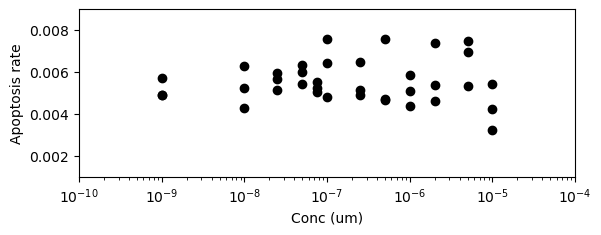

In [143]:
fig1 = plt.figure()
ax = fig1.add_subplot(2,1,1)

ax.set_xlabel('Conc (um)')
ax.set_ylabel('Apoptosis rate')
ax.set_xscale("log")
ax.set_xlim(1.0e-10, 1.0e-4)
ax.set_ylim(0.001,0.009)
#plt.text(0,4.5,title)
for conc in concs:
#     a_rates = []
#     for num in range(3):
# #         tmp_rates = calc_rates(population_dfs[conc][num])
#         a_rates.append(tmp_rates['a'])

    tmp_c = [conc*10e-7]*3
    ax.scatter(tmp_c,death_rate_di[conc], color='black')

In [144]:
import json

# e.g. file = './data.json' 
with open('C:\\Users\\olesk\\ECM_mod_output\\death_rate_di_55kpa_erl.json', 'w') as f: 
    json.dump(death_rate_di, f)